<a href="https://colab.research.google.com/github/Ludwig-Ivan/Panda/blob/main/comida.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Preparar el entorno

In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo " NO HAY GPU: Entorno de ejecución → Cambiar tipo → T4 GPU"
!pip install -q -U transformers huggingface_hub

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Conectar Google Drive
Ahí se guardan el modelo y la caché, para no perderlos si Colab se desconecta. Acepta el permiso que aparece.

In [3]:
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/n5k_runs'
import os; os.makedirs(OUT, exist_ok=True)
print('Resultados en', OUT)

Mounted at /content/drive
Resultados en /content/drive/MyDrive/n5k_runs


## 3. Configuración
Lo único que normalmente cambiarías. **Opción A** (recomendada): parte de los pesos de CalorieK y los sigue
entrenando. **Opción B**: entrena desde SigLIP2 base.

In [4]:
OPCION = "A"            # "A" = partir de CalorieK (recomendado) | "B" = desde SigLIP2 base

EPOCHS      = 15   if OPCION == "A" else 30
LR_HEAD     = 2e-4 if OPCION == "A" else 1e-3   # learning rate de la cabeza
LR_BACKBONE = 1e-5 if OPCION == "A" else 2e-5   # learning rate de SigLIP2 (bajo, para no "olvidar")
BATCH_SIZE  = 32        # bájalo a 16 si sale "CUDA out of memory"
IMG_SIZE    = 224
WARMUP_EPOCHS = 1
VAL_FRAC    = 0.1       # 10% del train oficial se usa para validación
MAX_CALORIES = None     # p. ej. 2000 para descartar platillos raros del entrenamiento
USAR_CACHE  = True      # guarda en Drive las fotos ya reducidas (~0.5 GB) para la próxima sesión
NUM_WORKERS = 2
SEED        = 0

BASE_URL = "https://storage.googleapis.com/nutrition5k_dataset/nutrition5k_dataset"
OUT = globals().get("OUT", "/content/runs")      # si no conectaste Drive, se guarda en /content/runs
RUN_DIR = f"{OUT}/caloriek_ft" if OPCION == "A" else f"{OUT}/siglip2"
CACHE_FILE = f"{OUT}/n5k_cache_{IMG_SIZE}.pt" if USAR_CACHE else None

import os, csv, io, json, math, random, time
import numpy as np, torch
from PIL import Image
from torchvision.transforms.v2 import functional as TF
NUTRIENTS = ["calorias", "masa", "grasa", "carbohidrato", "proteina"]
UNITS = {"calorias": "kcal", "masa": "g", "grasa": "g", "carbohidrato": "g", "proteina": "g"}
os.makedirs(RUN_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Opción", OPCION, "| dispositivo:", DEVICE, "| resultados en", RUN_DIR)

Opción A | dispositivo: cuda | resultados en /content/drive/MyDrive/n5k_runs/caloriek_ft


## 4. Leer los datos desde la web
Lee los metadatos y las listas oficiales de train/test, y baja las ~3,500 fotos cenitales **a memoria**
(reducidas a 224×224, unos 0.5 GB de RAM). No se guarda ninguna imagen en disco. Si `USAR_CACHE` está activo,
la siguiente vez se cargan desde Drive en segundos.

In [5]:
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

session = requests.Session()
_adapter = HTTPAdapter(pool_connections=64, pool_maxsize=64,
                       max_retries=Retry(total=5, backoff_factor=0.5, status_forcelist=[429, 500, 502, 503, 504]))
session.mount("http://", _adapter); session.mount("https://", _adapter)

def get_bytes(rel):
    """Lee un archivo del dataset por URL. Devuelve None si no existe (404)."""
    r = session.get(f"{BASE_URL}/{rel}", timeout=60)
    if r.status_code == 404:
        return None
    r.raise_for_status()
    return r.content

def parse_metadata(text, meta):
    """Cada fila: dish_id, calorías, masa, grasa, carbs, proteína, y luego 7 campos por ingrediente."""
    for row in csv.reader(io.StringIO(text)):
        if len(row) < 6:
            continue
        try:
            meta[row[0].strip()] = [float(x) for x in row[1:6]]
        except ValueError:
            pass

def label_ok(d):
    t = meta.get(d)
    return t is not None and t[1] > 0 and (MAX_CALORIES is None or t[0] <= MAX_CALORIES)

# 4.1 Metadatos (nutrientes de cada platillo)
meta = {}
for f in ["dish_metadata_cafe1.csv", "dish_metadata_cafe2.csv"]:
    data = get_bytes(f"metadata/{f}")
    if data is not None:
        parse_metadata(data.decode("utf-8"), meta)
assert meta, f"No pude leer los metadatos desde {BASE_URL}. ¿Hay internet?"
print(f"Metadatos: {len(meta)} platillos")

# 4.2 Splits oficiales
read_ids = lambda name: [l.strip() for l in get_bytes(f"dish_ids/splits/rgb_{name}_ids.txt").decode().splitlines() if l.strip()]
train_all = [d for d in read_ids("train") if label_ok(d)]
test_ids = [d for d in read_ids("test") if label_ok(d)]
random.Random(SEED).shuffle(train_all)
n_val = max(1, int(len(train_all) * VAL_FRAC))
val_ids, train_ids = train_all[:n_val], train_all[n_val:]

# 4.3 Fotos a memoria (en paralelo)
def fetch_photo(d):
    data = get_bytes(f"imagery/realsense_overhead/{d}/rgb.png")
    if data is None:
        return None
    x = torch.from_numpy(np.array(Image.open(io.BytesIO(data)).convert("RGB"))).permute(2, 0, 1).float()
    x = TF.resize(x, [IMG_SIZE, IMG_SIZE], antialias=True)
    return x.round().clamp(0, 255).to(torch.uint8)

store = {}
if CACHE_FILE and Path(CACHE_FILE).exists():
    c = torch.load(CACHE_FILE, map_location="cpu", weights_only=True)
    if c["img_size"] == IMG_SIZE:
        store = c["images"]
        print(f"Caché: {len(store)} fotos cargadas desde {CACHE_FILE}")

all_ids = list(dict.fromkeys(train_ids + val_ids + test_ids))
todo = [d for d in all_ids if d not in store]
missing, errors, t0 = [], [], time.time()
if todo:
    print(f"Bajando {len(todo)} fotos (32 conexiones en paralelo)...")
    with ThreadPoolExecutor(32) as ex:
        futs = {ex.submit(fetch_photo, d): d for d in todo}
        for i, f in enumerate(as_completed(futs), 1):
            d = futs[f]
            try:
                t = f.result()
                if t is None: missing.append(d)
                else: store[d] = t
            except Exception as e:
                errors.append((d, repr(e)))
            if i % 250 == 0 or i == len(todo):
                print(f"  {i}/{len(todo)}  ({time.time() - t0:.0f}s)", flush=True)
    if CACHE_FILE and len(todo) > len(missing) + len(errors):   # solo si hubo fotos nuevas
        torch.save({"img_size": IMG_SIZE, "images": store}, CACHE_FILE)
        print("Caché guardada en", CACHE_FILE)

if missing: print(f"{len(missing)} platillos no tienen foto en el bucket: se omiten")
if errors:  print(f"{len(errors)} fotos fallaron por red: se omiten (ej.: {errors[0][1][:100]})")
train_ids, val_ids, test_ids = ([d for d in ids if d in store] for ids in (train_ids, val_ids, test_ids))
print(f"Listo -> train {len(train_ids)} | val {len(val_ids)} | test {len(test_ids)} | "
      f"{sum(t.numel() for t in store.values()) / 1e6:.0f} MB en memoria")

Metadatos: 5006 platillos
Caché: 3262 fotos cargadas desde /content/drive/MyDrive/n5k_runs/n5k_cache_224.pt
Bajando 1506 fotos (32 conexiones en paralelo)...
  250/1506  (0s)
  500/1506  (1s)
  750/1506  (1s)
  1000/1506  (1s)
  1250/1506  (2s)
  1500/1506  (2s)
  1506/1506  (2s)
1506 platillos no tienen foto en el bucket: se omiten
Listo -> train 2494 | val 261 | test 507 | 491 MB en memoria


## 5. Dataset y aumento de datos
Convierte cada platillo en (imagen, 5 nutrientes). Durante el entrenamiento gira, voltea y cambia un poco
la luz de las fotos para que el modelo no memorice. No recorta, porque eso cambiaría la cantidad de comida.

In [ ]:
from torch.utils.data import Dataset, DataLoader

class N5kDataset(Dataset):
    def __init__(self, ids, train=False):
        self.ids, self.train = list(ids), train

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        d = self.ids[i]
        x = store[d].float() / 255.0
        if self.train:
            if random.random() < 0.5: x = TF.horizontal_flip(x)
            if random.random() < 0.5: x = TF.vertical_flip(x)
            x = TF.rotate(x, random.uniform(-180, 180), interpolation=TF.InterpolationMode.BILINEAR)
            x = TF.adjust_brightness(x, random.uniform(0.8, 1.2))
            x = TF.adjust_contrast(x, random.uniform(0.8, 1.2))
            x = TF.adjust_saturation(x, random.uniform(0.8, 1.2))
            x = TF.adjust_hue(x, random.uniform(-0.03, 0.03)).clamp(0, 1)
        x = (x - 0.5) / 0.5                      # normalización que espera SigLIP2
        return x, torch.tensor(meta[d], dtype=torch.float32), d

kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
train_dl = DataLoader(N5kDataset(train_ids, train=True), shuffle=True, drop_last=len(train_ids) > BATCH_SIZE, **kw)
val_dl   = DataLoader(N5kDataset(val_ids), **kw)
test_dl  = DataLoader(N5kDataset(test_ids), **kw)
x, y, _ = next(iter(val_dl))
print("Batch de ejemplo:", tuple(x.shape), "| etiquetas:", tuple(y.shape))

Batch de ejemplo: (32, 3, 224, 224) | etiquetas: (32, 5)


## 6. El modelo
SigLIP2 resume la foto en 768 números y la cabeza los convierte en los 5 nutrientes. La salida usa *softplus*,
así que nunca da valores negativos. En la opción A se cargan los pesos de CalorieK y se reordenan sus salidas,
porque CalorieK entrega `[kcal, masa, proteína, carbs, grasa]` y aquí usamos `[kcal, masa, grasa, carbs, proteína]`.

In [6]:
import torch.nn as nn, torch.nn.functional as F
from transformers import SiglipVisionConfig, SiglipVisionModel

SIGLIP_ID = "google/siglip2-base-patch16-224"
CALORIEK_TO_OURS = [0, 1, 4, 3, 2]

class NutritionHead(nn.Module):
    """Igual a la cabeza de CalorieK, para poder cargar sus pesos."""
    def __init__(self, d=768):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 768), nn.GELU(), nn.Dropout(.15),
                                 nn.Linear(768, 256), nn.GELU(), nn.Dropout(.10), nn.Linear(256, 5))
    def forward(self, x):
        return F.softplus(self.net(x))

class NutritionModel(nn.Module):
    def __init__(self, vision_config=None):
        super().__init__()
        self.backbone = (SiglipVisionModel(SiglipVisionConfig(**vision_config)) if vision_config
                         else SiglipVisionModel.from_pretrained(SIGLIP_ID))
        self.head = NutritionHead(self.backbone.config.hidden_size)
        self.register_buffer("scale", torch.ones(5))   # promedio de cada nutriente (o 1 con CalorieK)

    def forward(self, x):
        out = self.backbone(pixel_values=x)
        f = out.pooler_output if out.pooler_output is not None else out.last_hidden_state[:, 0]
        return self.head(f.float()) * self.scale       # valores en kcal y gramos

def load_caloriek(model):
    from huggingface_hub import hf_hub_download
    path = hf_hub_download("Dralkh/CalorieK", "caloriek.pt")
    try:
        state = torch.load(path, map_location="cpu", weights_only=True)
    except Exception:
        print("Aviso: el archivo de CalorieK necesita weights_only=False (ejecuta código del archivo). "
              "Si no confías en el autor, usa OPCION = 'B'.")
        state = torch.load(path, map_location="cpu", weights_only=False)
    model.backbone.load_state_dict(state["vision_state"])
    model.head.load_state_dict(state["head_state"])
    last = model.head.net[-1]
    with torch.no_grad():
        last.weight.copy_(last.weight[CALORIEK_TO_OURS].clone())
        last.bias.copy_(last.bias[CALORIEK_TO_OURS].clone())
        model.scale.fill_(1.0)                          # CalorieK ya predice en unidades reales

print("Clases del modelo definidas")

Clases del modelo definidas


## 7. Crear el modelo
Descarga SigLIP2 (y CalorieK en la opción A) desde Hugging Face.

In [ ]:
train_mean = torch.tensor([meta[d] for d in train_ids]).mean(0).clamp(min=1e-3)
model = NutritionModel()
if OPCION == "A":
    load_caloriek(model)
else:
    model.scale.copy_(train_mean)
model.to(DEVICE)
print(f"Modelo listo: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parámetros")

config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip2-base-patch16-224
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.embeddings.token_embedding.weight                 | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.se

caloriek.pt: reconstructing file:   0%|          |  0.00B /  375MB            

caloriek.pt: downloading bytes:           |  0.00B            

Modelo listo: 93.7 M parámetros


## 8. Entrenar
Cada época imprime el error en validación. La `*` marca la mejor época hasta ahora, que se guarda en
`best.pt` en tu Drive. Al final se evalúa en el **test oficial** (fotos que el modelo nunca vio).

In [ ]:
@torch.no_grad()
def evaluate(dl):
    model.eval()
    P, Y, ids = [], [], []
    for x, y, d in dl:
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            P.append(model(x.to(DEVICE)).float().cpu())
        Y.append(y); ids += list(d)
    P, Y = torch.cat(P), torch.cat(Y)
    mae = (P - Y).abs().mean(0); pct = 100 * mae / Y.mean(0)
    m = {n: {"mae": mae[i].item(), "pct_mae": pct[i].item()} for i, n in enumerate(NUTRIENTS)}
    m["mean_pct_mae"] = pct.mean().item()
    return m, P, Y, ids

fmt = lambda m: "  ".join(f"{n}: {m[n]['mae']:.1f}{UNITS[n]} ({m[n]['pct_mae']:.1f}%)" for n in NUTRIENTS)

if OPCION == "A":
    m0, *_ = evaluate(val_dl)
    print("CalorieK antes de entrenar (val):", f"%MAE medio {m0['mean_pct_mae']:.1f}% |", fmt(m0))

head_params = list(model.head.parameters())
head_ids = {id(p) for p in head_params}
opt = torch.optim.AdamW([{"params": [p for p in model.parameters() if id(p) not in head_ids], "lr": LR_BACKBONE},
                         {"params": head_params, "lr": LR_HEAD}], weight_decay=1e-4)
steps, warm = EPOCHS * len(train_dl), WARMUP_EPOCHS * len(train_dl)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / max(1, warm) if s < warm
                                          else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
loss_fn = nn.SmoothL1Loss(beta=0.1)
loss_scale = train_mean.to(DEVICE)          # cada nutriente se divide por su promedio: pesan parecido
config = {"img_size": IMG_SIZE, "opcion": OPCION, "vision_config": model.backbone.config.to_dict()}

best = float("inf")
for epoch in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); tot = n = 0
    for x, y, _ in train_dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            pred = model(x)
        loss = loss_fn(pred.float() / loss_scale, y / loss_scale)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * len(x); n += len(x)
    val, *_ = evaluate(val_dl)
    star = ""
    if val["mean_pct_mae"] < best:
        best, star = val["mean_pct_mae"], " *"
        torch.save({"model": model.state_dict(), "config": config}, f"{RUN_DIR}/best.pt")
    print(f"[{epoch:03d}/{EPOCHS}] loss {tot / n:.4f} | val %MAE medio {val['mean_pct_mae']:.1f}% | "
          f"{time.time() - t0:.0f}s{star}\n      {fmt(val)}", flush=True)

model.load_state_dict(torch.load(f"{RUN_DIR}/best.pt", map_location=DEVICE, weights_only=False)["model"])
test_m, P, Y, ids = evaluate(test_dl)
json.dump(test_m, open(f"{RUN_DIR}/test_metrics.json", "w"), indent=2)
with open(f"{RUN_DIR}/test_predictions.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["dish_id"] + [f"{k}_real" for k in NUTRIENTS] + [f"{k}_pred" for k in NUTRIENTS])
    for i, d in enumerate(ids):
        w.writerow([d] + [f"{v:.2f}" for v in Y[i].tolist()] + [f"{v:.2f}" for v in P[i].tolist()])
print("\n=== TEST ===\n" + fmt(test_m) + f"\n%MAE medio: {test_m['mean_pct_mae']:.1f}%")
print("Guardado en", RUN_DIR)

CalorieK antes de entrenar (val): %MAE medio 40.4% | calorias: 86.8kcal (37.6%)  masa: 82.7g (41.3%)  grasa: 5.0g (42.3%)  carbohidrato: 6.3g (36.9%)  proteina: 7.1g (43.9%)
[001/15] loss 0.3054 | val %MAE medio 30.8% | 48s *
      calorias: 52.7kcal (22.8%)  masa: 54.7g (27.3%)  grasa: 4.5g (38.0%)  carbohidrato: 5.8g (33.8%)  proteina: 5.2g (32.2%)
[002/15] loss 0.2838 | val %MAE medio 27.8% | 36s *
      calorias: 51.0kcal (22.0%)  masa: 58.2g (29.1%)  grasa: 4.0g (33.5%)  carbohidrato: 4.4g (26.0%)  proteina: 4.6g (28.3%)
[003/15] loss 0.2617 | val %MAE medio 26.0% | 36s *
      calorias: 50.6kcal (21.9%)  masa: 49.6g (24.8%)  grasa: 3.9g (32.5%)  carbohidrato: 4.2g (24.5%)  proteina: 4.2g (26.2%)
[004/15] loss 0.2390 | val %MAE medio 24.2% | 35s *
      calorias: 48.3kcal (20.9%)  masa: 44.5g (22.2%)  grasa: 3.4g (28.2%)  carbohidrato: 4.3g (25.5%)  proteina: 3.9g (24.2%)
[005/15] loss 0.2183 | val %MAE medio 27.2% | 33s
      calorias: 53.8kcal (23.3%)  masa: 46.6g (23.3%)  grasa

## 9. Resultados en el test oficial
**MAE** = cuánto se equivoca en promedio. **%MAE** = ese error como porcentaje del promedio real.
En la gráfica, cada punto es un platillo: cuanto más cerca de la diagonal, mejor.

,MAE,%MAE
calorias,44.4,17.4
masa,32.1,16.2
grasa,3.3,25.9
carbohidrato,4.5,23.1
proteina,4.1,23.3


AttributeError: 'DataFrame' object has no attribute 'calories_real'

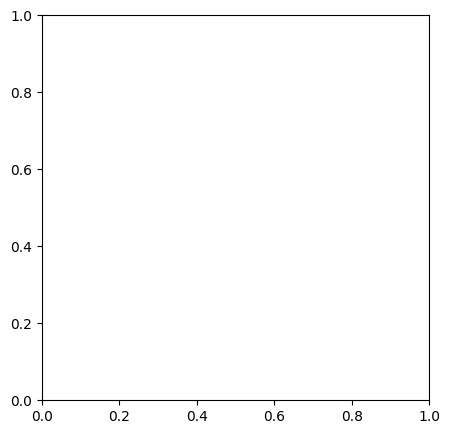

In [ ]:
import pandas as pd, matplotlib.pyplot as plt
m = json.load(open(f"{RUN_DIR}/test_metrics.json"))
display(pd.DataFrame({k: v for k, v in m.items() if isinstance(v, dict)}).T.round(1)
        .rename(columns={"mae": "MAE", "pct_mae": "%MAE"}))
df = pd.read_csv(f"{RUN_DIR}/test_predictions.csv")
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df.calories_real, df.calories_pred, s=8, alpha=0.5)
lim = max(df.calories_real.max(), df.calories_pred.max())
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set_xlabel("Calorías reales (kcal)"); ax.set_ylabel("Calorías predichas (kcal)")
ax.set_title("Test: predicho vs. real"); plt.show()

## 10. Probar con tus fotos
Sube una o varias fotos **tomadas desde arriba**, con el plato completo y buena luz.

*¿Volviste otro día?* No hace falta reentrenar ni volver a leer los datos: corre las secciones **1, 2, 3 y 6**
(con la misma `OPCION` que entrenaste) y luego esta.

In [15]:
from google.colab import files
ckpt = torch.load(f"{RUN_DIR}/best.pt", map_location="cpu", weights_only=False)
model = NutritionModel(ckpt["config"]["vision_config"])
model.load_state_dict(ckpt["model"]); model.to(DEVICE).eval()

def predecir(path):
    img = Image.open(path).convert("RGB")
    x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
    x = TF.resize(x, [ckpt["config"]["img_size"]] * 2, antialias=True)
    x = ((x - 0.5) / 0.5)[None].to(DEVICE)
    with torch.no_grad():
        y = model(x)[0].tolist()
    return dict(zip(NUTRIENTS, y))

for name in files.upload():
    r = predecir(name)
    ultima_prediccion, ultima_foto = r, name
    print(f"\n{name}")
    for k, v in r.items():
        print(f"  {k:9s} {v:8.1f} {UNITS[k]}")

Saving images.jpg to images (2).jpg

images (2).jpg
  calorias     949.6 kcal
  masa         598.3 g
  grasa         49.0 g
  carbohidrato     50.1 g
  proteina      80.1 g


## 11. ¿Cuánta actividad equivale a lo que comió?
Usa el **Compendio de Actividad Física para Adultos Mayores 2024** (personas de **60 años o más**). Cada actividad
tiene un valor **MET60**: cuántas veces más energía gasta que estar en reposo (1 MET60 = 2.7 mL de O₂ por kg por minuto).

**Fórmula:** kcal por minuto = MET60 × 2.7 × peso (kg) ÷ 200

- **Neto** (recomendado): solo las calorías *extra* que gasta por moverse, usando (MET60 − 1). El cuerpo ya quema
  calorías en reposo todo el día, así que esa parte no se le atribuye a la actividad.
- **Bruto**: todo lo que gasta durante la actividad, incluyendo el reposo. Da menos minutos; es lo que suelen mostrar las apps.

Esta sección funciona sola: no necesitas haber entrenado. Si corriste la sección 10, usa las calorías de la última foto.


In [10]:
import io, pandas as pd

# ==== Datos de la persona: déjalos en '' para que la celda te los pregunte ====
PESO_KG = ''        # en kg, por ejemplo 70
EDAD    = ''        # en años, 18 o más
NETO    = True      # True = solo calorías extra por la actividad (recomendado) | False = bruto
KCAL    = round(globals()["ultima_prediccion"]["calories"]) if "ultima_prediccion" in globals() else 500

def pedir_numero(valor, pregunta, minimo, maximo):
    """Usa `valor` si es válido; si está vacío o es inválido, lo pregunta hasta que sea correcto."""
    while True:
        texto = str(valor).strip() if str(valor).strip() != "" else input(pregunta).strip()
        try:
            n = float(texto.replace(",", "."))
            if minimo <= n <= maximo:
                return n
            print(f"Debe estar entre {minimo} y {maximo}.")
        except ValueError:
            print("Escribe solo el número, por ejemplo 70.")
        valor = ""

PESO_KG = pedir_numero(PESO_KG, "Peso en kg: ", 30, 300)
EDAD    = int(pedir_numero(EDAD, "Edad en años (18 o más): ", 18, 120))

COMPENDIO_CSV = """
codigo,categoria,actividad,met60,codigo_adulto,met_adulto,fuente_met_adulto,actividad_original
0101060,Bicicleta,"Bicicleta estática, general, esfuerzo moderado",5.3,01200,6.8,compendio adultos 2024,"Bicycling, stationary, general, moderate effort"
0101160,Bicicleta,"Bicicleta estática, 30-50 watts, esfuerzo moderado",4.3,01214,4.0,compendio adultos 2024,"Bicycling, stationary, 30-50 watts, moderate effort"
0101260,Bicicleta,"Bicicleta estática, 90-100 watts, esfuerzo vigoroso",6.3,01220,6.0,compendio adultos 2024,"Bicycling, stationary, 90-100 watts, vigorous effort"
0101360,Bicicleta,"Bicicleta estática, 101-160 watts, esfuerzo vigoroso",7.8,01228,8.0,compendio adultos 2024,"Bicycling, stationary, 101-160 watts, vigorous effort"
0101760,Bicicleta,"Bicicleta estática, 51-89 watts, esfuerzo moderado a vigoroso",4.5,01218,5.8,compendio adultos 2024,"Bicycling, stationary, 51-89 watts, moderate-to-vigorous effort"
0202260,Acondicionamiento,"Calistenia (lagartijas, abdominales, dominadas, zancadas), esfuerzo moderado",3.5,02022,3.8,compendio adultos 2024,"Calisthenics (e.g., push ups, sit ups, pull-ups, lunges), moderate effort"
0203560,Acondicionamiento,"Entrenamiento en circuito tipo parkour, esfuerzo moderado",4.5,02035,5.0,compendio adultos 2024,"Circuit training, Parcour-type, moderate effort"
0204760,Acondicionamiento,"Elíptica, esfuerzo ligero",3.0,,2.3,estimado desde MET60,"Elliptical trainer, light effort"
0205160,Acondicionamiento,"Pesas, sentadillas, esfuerzo ligero",3.0,,2.3,estimado desde MET60,"Resistance (weight) training, squats , light effort"
0205360,Acondicionamiento,"Entrenamiento de resistencia, general, esfuerzo ligero",2.3,,1.8,estimado desde MET60,"Resistance Training, general, light effort"
0205460,Acondicionamiento,"Pesas, varios ejercicios, 8-15 repeticiones con resistencia variada",4.3,02054,3.5,compendio adultos 2024,"Resistance (weight) training, multiple exercises, 8-15 repetitions at varied resistance"
0206260,Acondicionamiento,"Gimnasio, clases de acondicionamiento",5.0,02062,7.8,compendio adultos 2024,"Health club exercise, conditioning classes"
0206360,Acondicionamiento,"Gimnasio, clases de acondicionamiento en silla",3.8,,2.9,estimado desde MET60,"Health club exercise, conditioning classes, chair-based"
0207260,Acondicionamiento,"Remo estático, 50-99 watts, esfuerzo moderado a vigoroso",6.5,02071,5.0,compendio adultos 2024,"Rowing, stationary, 50 to 99 watts, moderate-to-vigorous effort"
0207360,Acondicionamiento,"Remo estático, 100-149 watts, esfuerzo vigoroso",9.0,02072,7.5,compendio adultos 2024,"Rowing, stationary, 100 to 149 watts, vigorous effort"
0211360,Acondicionamiento,"Ejercicio con pelota terapéutica (fitball), ejercicio en silla",3.5,02112,2.8,compendio adultos 2024,"Therapeutic exercise ball, Fitball exercise, chair exercise"
0219060,Acondicionamiento,"Yoga, general",2.5,02175,2.3,compendio adultos 2024,"Yoga, general"
0219160,Acondicionamiento,"Yoga en silla, general",2.8,,2.2,estimado desde MET60,"Yoga, chair, general"
0221060,Acondicionamiento,"Tai chi, general",3.8,15670,3.3,compendio adultos 2024,"Tai Chi, general"
0221160,Acondicionamiento,"Tai chi en silla, general",2.8,15672,1.5,compendio adultos 2024,"Tai Chi, chair, general"
0303060,Baile,"Baile de salón (tango, vals lento, foxtrot)",6.0,03042,6.0,compendio adultos 2024,"Ballroom Dance (tango, slow waltz, foxtrot)"
0303160,Baile,"Clase de baile, general",6.3,03010,5.0,compendio adultos 2024,"Dance class, General"
0303260,Baile,"Baile fluido (mazurca, vals vienés, polka)",7.3,,5.6,estimado desde MET60,"Smooth Dance (Mazurka, Viennese Walk, Polka)"
0501060,Hogar,"Limpieza, barrer alfombra o pisos, general",4.3,05010,3.3,compendio adultos 2024,"Cleaning, sweeping carpet or floors, general"
0502160,Hogar,"Limpieza, trapear de pie, esfuerzo moderado",4.3,05021,3.5,compendio adultos 2024,"Cleaning, mopping, standing, Moderate effort"
0502260,Hogar,"Limpiar o lavar ventanas, general",3.5,05022,3.3,compendio adultos 2024,"Cleaning windows, washing windows, general"
0502360,Hogar,"Limpieza, trapear de pie, esfuerzo ligero",3.0,05023,2.5,compendio adultos 2024,"Cleaning, mopping, standing, light effort"
0503260,Hogar,"Sacudir o pulir muebles, general",4.0,05032,2.5,compendio adultos 2024,"Dusting or polishing furniture, general"
0504060,Hogar,"Limpieza, sacar la basura",4.5,05040,2.5,compendio adultos 2024,"Cleaning, carrying out trash"
0504160,Hogar,"Lavar trastes, de pie o en general",2.5,05041,2.0,compendio adultos 2024,"Wash dishes, standing or in general (not broken into stand/walk components)"
0504360,Hogar,"Limpieza, aspirar, general, esfuerzo moderado",4.3,05043,3.0,compendio adultos 2024,"Cleaning, vacuuming, general, moderate effort"
0505160,Hogar,"Cocinar, servir comida, poner la mesa (de pie o caminando)",2.8,05052,2.3,compendio adultos 2024,"Cooking, serving food, setting table, implied walking or standing"
0505560,Hogar,"Guardar despensa o trastes (cargar bolsas, acomodar en alacenas)",3.0,05055,2.5,compendio adultos 2024,"Putting away groceries/dishes (e.g. carrying groceries, storing dishes in cabinet),"
0506060,Hogar,"Hacer el súper, con o sin carrito, de pie o caminando",3.8,05060,3.3,compendio adultos 2024,"Food shopping with or without a grocery cart, standing or walking"
0507060,Hogar,Planchar,2.8,05070,1.8,compendio adultos 2024,Ironing
0509060,Hogar,"Lavandería: doblar o colgar ropa, meterla a la lavadora/secadora, hacer maleta, lavar a mano; de pie, esfuerzo ligero",2.0,05090,2.3,compendio adultos 2024,"Laundry, fold or hang clothes, put clothes in washer or dryer, packing suitcase, washing clothes by hand, implied standing, light effort"
0509260,Hogar,"Lavandería: tender ropa, lavar a mano, esfuerzo moderado",3.5,05092,4.0,compendio adultos 2024,"Laundry, hanging wash, washing clothes by hand, moderate effort"
0510060,Hogar,"Tender la cama, cambiar sábanas",4.0,05100,3.0,compendio adultos 2024,"Making bed, changing linens"
0512060,Hogar,"Mover muebles u objetos de la casa, cargar cajas",5.0,05120,5.8,compendio adultos 2024,"Moving furniture, household items, carrying boxes"
0612760,Reparaciones,"Reparaciones en casa, general, esfuerzo moderado",4.0,06127,4.5,compendio adultos 2024,"Home repair, general, moderate effort"
0701060,Inactividad,Acostado viendo televisión,1.3,07009,1.0,compendio adultos 2024,Lying quietly and watching television
0701160,Inactividad,"Acostado sin hacer nada, despierto en la cama",1.3,07011,1.0,compendio adultos 2024,"Lying quietly, doing nothing, lying in bed awake,"
0702060,Inactividad,Sentado viendo televisión,1.3,07020,1.0,compendio adultos 2024,Sitting quietly and watching television
0702160,Inactividad,"Sentado en reposo, general",1.3,07021,1.0,compendio adultos 2024,"Sitting quietly, general"
0704060,Inactividad,"De pie en reposo, haciendo fila",1.5,07040,1.3,compendio adultos 2024,"Standing quietly, standing in a line"
0805060,Jardín,"Cavar, palear, rellenar jardín, hacer composta, esfuerzo moderado",4.8,08050,5.0,compendio adultos 2024,"Digging, spading, filling garden, compositing, moderate effort"
0805260,Jardín,"Cavar, palear, rellenar jardín, hacer composta, esfuerzo vigoroso",7.3,08052,7.3,compendio adultos 2024,"Digging, spading, filling garden, composting, vigorous effort"
0806160,Jardín,"Jardinería, construir un arriate",4.8,,3.7,estimado desde MET60,"Gardening, building garden bed"
0806560,Jardín,"Jardinería, mezclar tierra",3.0,,2.3,estimado desde MET60,"Gardening, mixing soil"
0809160,Jardín,Poner mantillo (mulch),3.5,,2.7,estimado desde MET60,Laying mulch
0809560,Jardín,"Podar el pasto, general",6.8,08095,5.5,compendio adultos 2024,"Mowing lawn, general"
0813560,Jardín,"Plantar, trasplantar o sembrar plántulas, esfuerzo ligero a moderado",3.3,08135,2.6,compendio adultos 2024,"Planting, potting, transplanting seedlings or plants, light-moderate effort"
0816060,Jardín,"Rastrillar pasto u hojas, esfuerzo moderado",4.0,08160,4.0,compendio adultos 2024,"Raking lawn or leaves, moderate effort"
0821060,Jardín,Podar arbustos o árboles con tijera manual,3.3,08210,3.8,compendio adultos 2024,"Trimming shrubs or trees, manual cutter"
0821560,Jardín,"Podar con cortadora eléctrica o usar sopladora, esfuerzo moderado",3.8,08215,3.3,compendio adultos 2024,"Trimming shrubs or trees, power cutter, using leaf blower, edge, moderate effort"
0822060,Jardín,Caminar aplicando fertilizante,5.3,08220,3.0,compendio adultos 2024,"Walking, applying fertilizer"
0823060,Jardín,"Regar el pasto o el jardín, de pie o caminando",3.3,08230,4.0,compendio adultos 2024,"Watering lawn or garden, standing or walking"
0823960,Jardín,"Deshierbar, cultivar el jardín, esfuerzo ligero a moderado",4.8,08239,3.8,compendio adultos 2024,"Weeding, cultivating garden, light-to-moderate effort"
0824660,Jardín,"Recoger fruta de árboles o frutas/verduras, esfuerzo moderado",3.5,08246,3.5,compendio adultos 2024,"Picking fruit off trees, picking fruits/vegetables, moderate effort"
0826160,Jardín,"Trabajo de jardín, general, esfuerzo moderado",5.0,08261,4.0,compendio adultos 2024,"Yard work, general, moderate effort"
0826560,Jardín,"Jardinería, general, esfuerzo moderado",3.8,08245,3.8,compendio adultos 2024,"Gardening, general, moderate effort"
0901060,Varios,"Jugar cartas, sentado",1.5,09010,1.5,compendio adultos 2024,"Card playing, sitting"
1101060,Trabajo,Escribir a máquina o en computadora,1.5,11770,1.3,compendio adultos 2024,"Typing, electric, manual or computer"
1202860,Correr,Correr a 5.8 km/h (10.5 min/km),8.5,,6.6,estimado desde MET60,"Running, 3.6 mph (17 min/mile)"
1207060,Correr,Correr a 11.3 km/h (5.3 min/km),15.8,12070,11.0,compendio adultos 2024,"Running, 7 mph (8.5 min/mile)"
1302060,Cuidado personal,"Vestirse o desvestirse, de pie o sentado",3.0,13020,2.8,compendio adultos 2024,"Dressing, undressing, standing or sitting"
1304060,Cuidado personal,"Arreglo personal: lavarse las manos, rasurarse, cepillarse, maquillarse",2.8,13040,2.0,compendio adultos 2024,"Grooming, washing hands, shaving, brushing teeth, putting on make-up, sitting or standing"
1528560,Deportes,"Golf caminando, jalando los palos",4.3,15285,4.5,compendio adultos 2024,"Golf, walking, pulling clubs"
1540060,Deportes,Equitación simulada,2.8,15406,2.1,compendio adultos 2024,"Horseback riding, simulated"
1552560,Deportes,Pickleball competitivo,5.3,,4.1,estimado desde MET60,"Pickleball, competitive"
1606060,Transporte,"Caminar como transporte, 4.5-5.1 km/h, plano, ritmo moderado",4.3,16060,3.5,compendio adultos 2024,"Walking for transportation, 2.8-3.2 mph, level, moderate pace, firm surface"
1713360,Caminar,"Subir escaleras, ritmo lento",4.0,17133,4.5,compendio adultos 2024,"Stair climbing, slow pace"
1713460,Caminar,"Subir escaleras, ritmo rápido",6.5,17134,9.3,compendio adultos 2024,"Stair climbing, fast pace"
1713560,Caminar,Subir escaleras con bastón,2.0,,1.5,estimado desde MET60,"Ascending stairs, using cane"
1713660,Caminar,Subir escaleras con andadera estándar,3.0,,2.3,estimado desde MET60,"Ascending stairs, using standard walker"
1713760,Caminar,Subir escaleras con andadera con ruedas,3.3,,2.5,estimado desde MET60,"Ascending stairs, using wheeled walker"
1715160,Caminar,"Caminar a menos de 1.6 km/h, plano, paseo muy lento",3.0,17340,2.1,compendio adultos 2024,"Walking, less than 1.0 mph, level, strolling, very slow"
1715260,Caminar,"Caminar a 1.6-3.1 km/h, plano, ritmo lento",4.0,17346,2.8,compendio adultos 2024,"Walking, 1.0 to 1.9 mph, level, slow pace, firm surface"
1715360,Caminar,"Caminar a 3.2 km/h, plano, ritmo lento",3.8,17152,2.8,compendio adultos 2024,"Walking, 2.0 mph, level, slow pace, firm surface"
1717060,Caminar,"Caminar a 3.5-4.3 km/h, plano",4.5,17170,3.0,compendio adultos 2024,"Walking, 2.2 to 2.7 mph, level, firm surface"
1719060,Caminar,"Caminar a 4.5-5.1 km/h, plano, ritmo moderado",5.3,17190,3.8,compendio adultos 2024,"Walking, 2.8 to 3.2 mph, level, moderate pace, firm surface"
1720060,Caminar,"Caminar a 5.3-6.0 km/h, plano, rápido, como ejercicio",6.0,17200,4.8,compendio adultos 2024,"Walking, 3.3 to 3.7 mph, level, brisk, firm surface, walking for exercise"
1720160,Caminar,"Caminar a paso rápido, general",5.5,17200,4.8,compendio adultos 2024,"Walking, brisk pace, general"
1720960,Caminar,Caminar a 2.4-3.2 km/h con pendiente de 2.5-5%,5.0,,3.9,estimado desde MET60,"Walking, 1.5 to 2.0 mph, 2.5 to 5% grade"
1722060,Caminar,"Caminar a 6.4-6.8 km/h, plano, muy rápido",7.3,17220,5.5,compendio adultos 2024,"Walking, 4.0 to 4.2 mph, level, firm surface, very brisk pace"
1723060,Caminar,"Caminar a 7.2 km/h, plano, muy, muy rápido",9.0,17230,7.0,compendio adultos 2024,"Walking, 4.5 mph, level, firm surface, very, very brisk"
1726260,Caminar,"Caminar tranquilo, al ritmo propio, general",4.0,17255,4.0,compendio adultos 2024,"Walking, leasurly, self-selected pace, general"
1731060,Caminar,"Caminata nórdica (con bastones), como ejercicio",7.0,17302,4.3,compendio adultos 2024,"Walking, for exercise, with ski poles, Nordic walking,"
1733060,Caminar,Caminar con bastón,3.5,,2.7,estimado desde MET60,"Walking, with a cane"
1734060,Caminar,Caminar con andadera estándar,3.5,,2.7,estimado desde MET60,"Walking, with standard walker"
1735060,Caminar,Caminar con andadera con ruedas,3.5,,2.7,estimado desde MET60,"Walking, with wheeled Walker"
1916060,Invierno,"Esquí alpino o snowboard, esfuerzo moderado (solo tiempo activo)",5.3,19160,6.3,compendio adultos 2024,"Skiing, downhill, alpine or snowboarding, moderate effort, general, active time only"
1917060,Invierno,"Esquí alpino o snowboard, esfuerzo vigoroso (solo tiempo activo)",6.8,19170,8.0,compendio adultos 2024,"Skiing, downhill, alpine or snowboarding, vigorous effort, general, active time only"
1925460,Invierno,"Palear nieve a mano, esfuerzo vigoroso",8.0,19254,7.5,compendio adultos 2024,"Snow shoveling, by hand, vigorous effort"
2210060,Videojuegos,Videojuego sentado con control (inactivo),1.8,22040,1.3,compendio adultos 2024,"Seated, video game, handheld controller (inactive)"
2220060,Videojuegos,"Videojuego de esfuerzo ligero (Wii Fit, yoga, boliche, etc.)",2.8,22160,2.3,compendio adultos 2024,"Video game, light effort (Wii Fit, yoga, bowling, etc)"
2230060,Videojuegos,"Videojuego activo con sensor de movimiento, tren superior (ligero a moderado)",3.5,22200,3.0,compendio adultos 2024,"Active video game, motion sensing game/using upper body (light to moderate effort)"
2240060,Videojuegos,"Videojuego activo con sensor de movimiento, cuerpo completo (moderado)",5.5,22240,4.0,compendio adultos 2024,"Active video game, motion sensing game/using total body (moderate effort)"
2250060,Videojuegos,"Videojuego activo con sensor de movimiento, cuerpo completo (moderado a vigoroso)",7.8,22280,5.0,compendio adultos 2024,"Active video game, motion sensing game/using total body (moderate to vigorous effort)"
"""
compendio = pd.read_csv(io.StringIO(COMPENDIO_CSV), dtype={"codigo": str, "codigo_adulto": str})

ADULTO_MAYOR = EDAD >= 60
O2_REPOSO = 2.7 if ADULTO_MAYOR else 3.5            # mL de O2 por kg por minuto que vale 1 MET
compendio["met"] = compendio["met60"] if ADULTO_MAYOR else compendio["met_adulto"]
compendio["nota"] = "" if ADULTO_MAYOR else compendio["fuente_met_adulto"].map(
    lambda f: "estimado" if f.startswith("estimado") else "")

def kcal_por_minuto(met, peso=None, neto=None):
    peso = PESO_KG if peso is None else peso
    neto = NETO if neto is None else neto
    return (met - 1 if neto else met) * O2_REPOSO * peso / 200

def minutos_para_quemar(kcal, peso=None, neto=None, categoria=None, max_met=None):
    """Tabla con los minutos que necesita cada actividad para gastar `kcal`."""
    neto = NETO if neto is None else neto
    t = compendio.copy()
    if categoria: t = t[t.categoria == categoria]
    if max_met:   t = t[t.met <= max_met]
    if neto:      t = t[t.met > 1.0]                   # en reposo no hay gasto "extra"
    t["kcal_por_min"] = kcal_por_minuto(t.met, peso, neto).round(2)
    t["minutos"] = (kcal / t.kcal_por_min).round(0).astype(int)
    cols = ["codigo", "categoria", "actividad", "met", "kcal_por_min", "minutos"] + ([] if ADULTO_MAYOR else ["nota"])
    return t.sort_values("minutos")[cols]

def plan(kcal, actividades, peso=None, neto=None):
    """actividades = [(codigo, minutos), ...]. Dice cuánto gasta cada una y cuánto falta."""
    filas = []
    for codigo, mins in actividades:
        a = compendio[compendio.codigo == codigo].iloc[0]
        filas.append({"actividad": a.actividad, "minutos": mins,
                      "kcal": round(kcal_por_minuto(a.met, peso, neto) * mins)})
    df = pd.DataFrame(filas)
    total = int(df.kcal.sum())
    display(df)
    print(f"Total: {total} kcal de {kcal} -> " + (f"faltan {kcal - total} kcal" if total < kcal else "meta cubierta"))
    return df

fuente = ("Compendio para Adultos Mayores  (MET60)" if ADULTO_MAYOR
          else "Compendio de Actividad Física para Adultos ")
print(f"Persona de {EDAD} años y {PESO_KG:g} kg | comida de {KCAL} kcal | cálculo {'neto' if NETO else 'bruto'}")
print(f"Valores: {fuente}")
if EDAD == 18:
    print("Nota: el compendio de adultos se basa en personas de 19 a 59 años; para 18 años es una buena aproximación.")
print(f"Referencia: en reposo total su cuerpo gasta ~{round(O2_REPOSO * PESO_KG * 1440 / 200)} kcal al día.\n")

comunes = ["1719060", "1715360", "0101060", "0221060", "0219060", "0303160", "0826560", "0504360"]
print("Actividades comunes:")
display(minutos_para_quemar(KCAL).query("codigo in @comunes"))

Peso en kg: 777
Debe estar entre 30 y 300.
Peso en kg: 200
Edad en años (18 o más): 30
Persona de 30 años y 200 kg | comida de 500 kcal | cálculo neto
Valores: Compendio de Actividad Física para Adultos 
Referencia: en reposo total su cuerpo gasta ~5040 kcal al día.

Actividades comunes:


,codigo,categoria,actividad,met,kcal_por_min,minutos,nota
0,0101060,Bicicleta,"Bicicleta estática, general, esfuerzo moderado",6.8,20.30,25,
21,0303160,Baile,"Clase de baile, general",5.0,14.00,36,
80,1719060,Caminar,"Caminar a 4.5-5.1 km/h, plano, ritmo moderado",3.8,9.80,51,
60,0826560,Jardín,"Jardinería, general, esfuerzo moderado",3.8,9.80,51,
18,0221060,Acondicionamiento,"Tai chi, general",3.3,8.05,62,
30,0504360,Hogar,"Limpieza, aspirar, general, esfuerzo moderado",3.0,7.00,71,
78,1715360,Caminar,"Caminar a 3.2 km/h, plano, ritmo lento",2.8,6.30,79,
16,0219060,Acondicionamiento,"Yoga, general",2.3,4.55,110,




Categoría: “Todas” o una en particular (Caminar, Jardín, Hogar…).
Actividad: ordenadas de la más suave a la más intensa. Empieza en “Caminar a ritmo moderado”.
Calorías: toma automáticamente las de tu última foto (sección 10), y también puedes cambiarlas a mano

In [17]:
# ==== Elige una actividad y calcula el tiempo para quemar las calorías del platillo ====
# Requiere haber corrido antes:
#   - la sección 10 (subir la foto: de ahí salen las calorías)
#   - la sección 11 (peso, edad y tabla de actividades)
import ipywidgets as widgets
from IPython.display import display, clear_output

def calorias_de_la_foto():
    """Calorías que el modelo estimó en la última foto de la sección 10 (None si aún no hay)."""
    pred = globals().get("ultima_prediccion")
    return round(pred["calorias"]) if pred else None

def opciones_de(categoria):
    t = compendio if categoria == "Todas" else compendio[compendio.categoria == categoria]
    if NETO:
        t = t[t.met > 1.0]                      # en reposo no hay gasto "extra"
    t = t.sort_values(["met", "actividad"])           # de más suave a más intensa
    return [(f"{r.actividad}  ({r.met:g} MET)", r.codigo) for r in t.itertuples()]

w_cat  = widgets.Dropdown(options=["Todas"] + sorted(compendio.categoria.unique()), value="Todas",
                          description="Categoría:", style={"description_width": "90px"})
w_act  = widgets.Dropdown(options=opciones_de("Todas"), description="Actividad:",
                          style={"description_width": "90px"}, layout=widgets.Layout(width="95%"))
salida = widgets.Output()

def mostrar(*_):
    with salida:
        clear_output()
        kcal = calorias_de_la_foto()
        if kcal is None:
            print("Todavía no hay calorías: primero sube la foto del platillo en la sección 10 "
                  "y luego vuelve a correr esta celda.")
            return
        if w_act.value is None:
            print("Elige una actividad.")
            return
        a = compendio[compendio.codigo == w_act.value].iloc[0]
        tasa = kcal_por_minuto(a.met)
        minutos = round(kcal / tasa)
        h, m = divmod(minutos, 60)
        tiempo = f"{h} h {m} min" if h else f"{m} min"
        foto = globals().get("ultima_foto")
        print(f"Platillo:   {kcal} kcal" + (f"  (foto: {foto})" if foto else "  (última foto de la sección 10)"))
        print(f"Actividad:  {a.actividad}")
        print(f"Intensidad: {a.met:g} MET  ->  {tasa:.1f} kcal por minuto "
              f"({'neto' if NETO else 'bruto'}, {EDAD} años, {PESO_KG:g} kg)")
        print(f"\nTiempo estimado para quemar {kcal} kcal:  {tiempo}")
        if a.get("nota", "") == "estimado":
            print("Nota: para esta actividad el valor de adulto es estimado (no está en el compendio de adultos).")
        if a.met >= 6:
            print("Actividad vigorosa: si no se practica con regularidad, conviene consultarlo antes con un médico.")

def cambiar_categoria(cambio):
    w_act.options = opciones_de(cambio["new"])

if "1719060" in [c for _, c in w_act.options]:
    w_act.value = "1719060"                         # empieza en: caminar a ritmo moderado

w_cat.observe(cambiar_categoria, names="value")
w_act.observe(mostrar, names="value")

display(widgets.VBox([w_cat, w_act, salida]))
mostrar()